# 3C. LSTM Autoencoder - Energy Consumption
Sliding windows -> LSTM AE -> reconstruction error.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler

In [2]:
df = pd.read_csv("../datasets/AutoEncoder/Energy Consumption/energy consumption.csv")
df = df.dropna()

y = df["Anomaly_Label"].to_numpy().astype(int)
x = df.drop(columns=["Timestamp", "Anomaly_Label"]).to_numpy().astype("float32")

scaler = MinMaxScaler()
x = scaler.fit_transform(x)

# sliding windows (W=10)
W = 10
Xw = []
yw = []
for i in range(len(x) - W + 1):
    Xw.append(x[i:i+W])
    yw.append(y[i:i+W].max())
Xw = np.array(Xw)
yw = np.array(yw)

Xw_norm = Xw[yw == 0]
print("windows:", Xw.shape, "normal:", Xw_norm.shape)

windows: (4991, 10, 5) normal: (3527, 10, 5)


In [3]:
model = keras.Sequential([
    layers.Input(shape=(10, Xw.shape[2])),
    layers.LSTM(16, activation="relu"),
    layers.RepeatVector(10),
    layers.LSTM(16, activation="relu", return_sequences=True),
    layers.TimeDistributed(layers.Dense(Xw.shape[2])),
])
model.compile(optimizer="adam", loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 10, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 10, 16)         │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 10, 5)          │            85 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,605 (14.08 KB)

 Trainable params: 3,605 (14.08 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(Xw_norm, Xw_norm, epochs=10, validation_split=0.1)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0921 - val_loss: 0.0292
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0216 - val_loss: 0.0172
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0166 - val_loss: 0.0160
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0160 - val_loss: 0.0159
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0159 - val_loss: 0.0157
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0158 - val_loss: 0.0156
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0157 - val_loss: 0.0156
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0156 - val_loss: 0.0155
Epoch 9/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0155 - val_loss: 0.0152
Epoch 10/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0153 - val_loss: 0.0151


In [5]:
recon = model.predict(Xw)
err = np.mean((Xw - recon) ** 2, axis=(1, 2))

threshold = np.quantile(err[yw == 0], 0.95)
y_pred = (err > threshold).astype(int)

print(f"anomalies predicted: {y_pred.sum()}  actual: {yw.sum()}")
print(f"threshold: {threshold:.6f}")

anomalies predicted: 471  actual: 1464
threshold: 0.020774


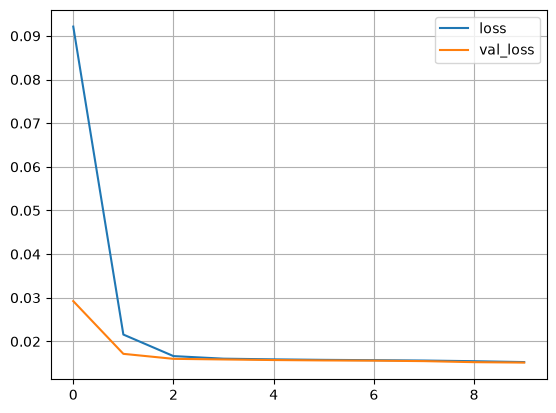

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()